In [ ]:
pip install tensorflow statsmodels matplotlib scikit-learn

In [ ]:
# RNN (LSTM) lab for economics dataset — ready to run in Colab / Jupyter / local env

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping
import statsmodels.api as sm



In [ ]:
# 1. Load dataset
data = sm.datasets.macrodata.load_pandas().data
series = data[['year','quarter','realgdp']].copy()
series['date'] = pd.to_datetime(series['year'].astype(int).astype(str) + 'Q' + series['quarter'].astype(int).astype(str))
series.set_index('date', inplace=True)
series = series[['realgdp']].rename(columns={'realgdp':'RGDP'})

# Quick peek
print("Sample rows:")
display(series.head())




Sample rows:


/tmp/ipython-input-2349920842.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  series['date'] = pd.to_datetime(series['year'].astype(int).astype(str) + 'Q' + series['quarter'].astype(int).astype(str))


,RGDP
date,
1959-01-01,2710.349
1959-04-01,2778.801
1959-07-01,2775.488
1959-10-01,2785.204
1960-01-01,2847.699


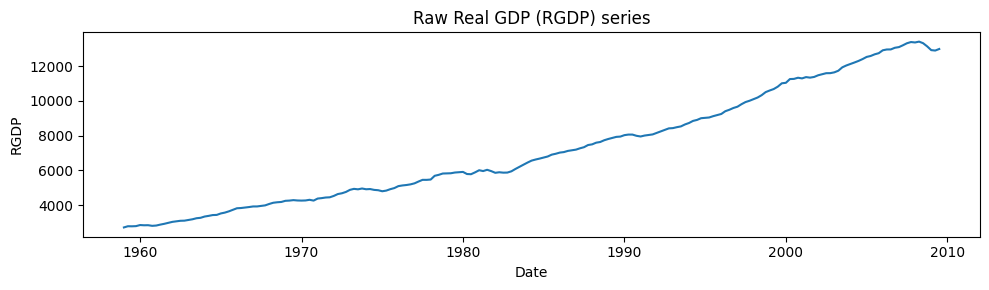

In [ ]:
# 2. Plot raw RGDP
plt.figure(figsize=(10,3))
plt.plot(series.index, series['RGDP'])
plt.title("Raw Real GDP (RGDP) series")
plt.xlabel("Date")
plt.ylabel("RGDP")
plt.tight_layout()
plt.show()



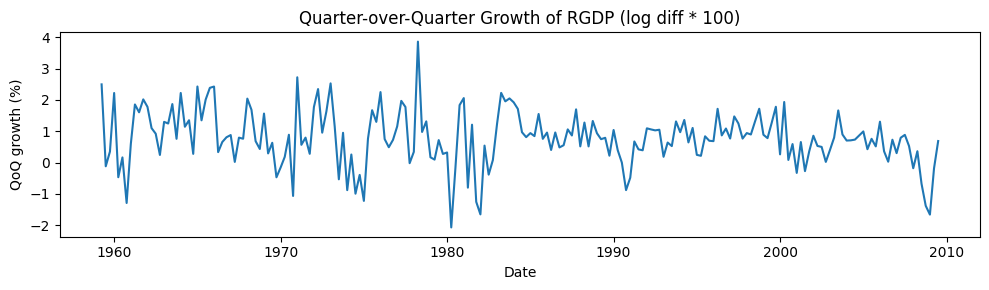

In [ ]:
# 3. Transform to QoQ growth (log diff * 100)
series['log_RGDP'] = np.log(series['RGDP'])
series['qoq_growth'] = series['log_RGDP'].diff() * 100
series = series.dropna()

plt.figure(figsize=(10,3))
plt.plot(series.index, series['qoq_growth'])
plt.title("Quarter-over-Quarter Growth of RGDP (log diff * 100)")
plt.xlabel("Date")
plt.ylabel("QoQ growth (%)")
plt.tight_layout()
plt.show()



Total: 202, Train: 161, Test: 41


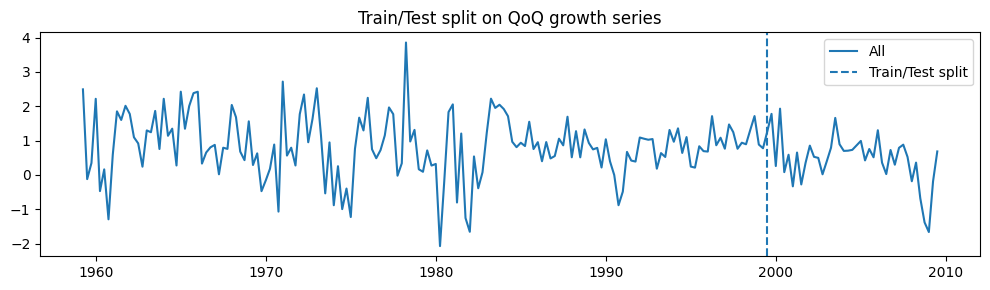

In [ ]:
# 4. Train/test split (80/20)
n = len(series)
train_size = int(n * 0.8)
train = series.iloc[:train_size]
test = series.iloc[train_size:]
print(f"Total: {n}, Train: {len(train)}, Test: {len(test)}")

plt.figure(figsize=(10,3))
plt.plot(series.index, series['qoq_growth'], label='All')
plt.axvline(series.index[train_size], linestyle='--', label='Train/Test split')
plt.title("Train/Test split on QoQ growth series")
plt.legend()
plt.tight_layout()
plt.show()



In [ ]:
# 5. Scale using MinMax on training values
scaler = MinMaxScaler(feature_range=(0,1))
train_vals = train[['qoq_growth']].values
test_vals = test[['qoq_growth']].values
scaler.fit(train_vals)
train_scaled = scaler.transform(train_vals)
test_scaled = scaler.transform(test_vals)



In [ ]:
# 6. Make sequences (past SEQ_LEN -> next)
def make_sequences(data_array, seq_len=8):
    X, y = [], []
    for i in range(len(data_array) - seq_len):
        X.append(data_array[i:i+seq_len, 0])
        y.append(data_array[i+seq_len, 0])
    return np.array(X), np.array(y)

SEQ_LEN = 8
X_train, y_train = make_sequences(train_scaled, SEQ_LEN)
# Build test sequences by appending tail of train to test so sequences overlap correctly
combined = np.vstack([train_scaled[-SEQ_LEN:], test_scaled])
X_test, y_test = make_sequences(combined, SEQ_LEN)

print("Shapes:", X_train.shape, y_train.shape, X_test.shape, y_test.shape)



Shapes: (153, 8) (153,) (41, 8) (41,)


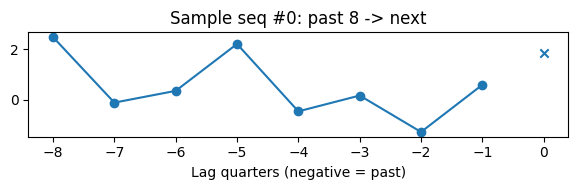

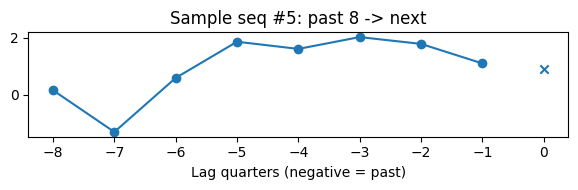

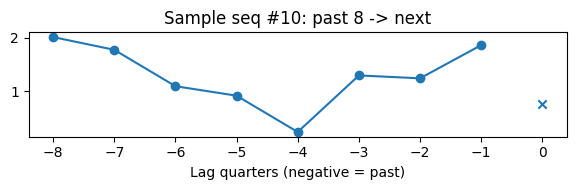

In [ ]:
# 7. Visualize sample sequences (unscaled)
sample_idx = [0, 5, 10]
for i in sample_idx:
    seq = scaler.inverse_transform(X_train[i].reshape(-1,1)).flatten()
    target = scaler.inverse_transform(y_train[i].reshape(-1,1)).flatten()[0]
    plt.figure(figsize=(6,2))
    plt.plot(range(-SEQ_LEN,0), seq, marker='o')
    plt.scatter([0], [target], marker='x')
    plt.title(f"Sample seq #{i}: past {SEQ_LEN} -> next")
    plt.xlabel("Lag quarters (negative = past)")
    plt.tight_layout()
    plt.show()



In [ ]:
# 8. Prepare for LSTM
X_train_r = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test_r = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# 9. Build model
model = Sequential([
    LSTM(32, input_shape=(SEQ_LEN,1)),
    Dense(16, activation='relu'),
    Dense(1)
])
model.compile(optimizer='adam', loss='mse')
model.summary()



/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 10. Train
es = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
history = model.fit(X_train_r, y_train, epochs=60, batch_size=8, validation_split=0.15, callbacks=[es], verbose=1)



Epoch 1/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - loss: 0.1623 - val_loss: 0.0421
Epoch 2/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0472 - val_loss: 0.0072
Epoch 3/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0350 - val_loss: 0.0056
Epoch 4/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0217 - val_loss: 0.0045
Epoch 5/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0249 - val_loss: 0.0048
Epoch 6/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0261 - val_loss: 0.0051
Epoch 7/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0272 - val_loss: 0.0053
Epoch 8/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0282 - val_loss: 0.0045
Epoch 9/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0248 - val_loss: 0.0051
Epoch 10/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0234 - val_loss: 0.0048
Epoch 11/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0272 - val_loss: 0.0055
Epoch 12/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0249 - va

In [ ]:
# 11. Plot training history
plt.figure(figsize=(8,3))
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.title("Training history (MSE)")
plt.xlabel("Epoch")
plt.legend()
plt.tight_layout()
plt.show()



2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


,actual_qoq,predicted_qoq
date,,
1999-07-01,1.263644,1.051153
1999-10-01,1.780193,1.060629
2000-01-01,0.261048,1.146839
2000-04-01,1.931859,1.065210
2000-07-01,0.083573,1.151428
2000-10-01,0.590001,1.034916
2001-01-01,-0.330271,0.949587
2001-04-01,0.653599,0.814728
2001-07-01,-0.274542,0.794425


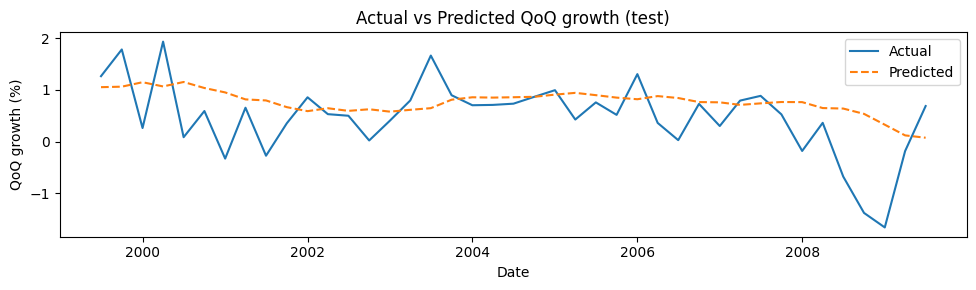

In [ ]:
# 12. Predict on test
pred_scaled = model.predict(X_test_r)
pred = scaler.inverse_transform(pred_scaled).flatten()
y_test_inv = scaler.inverse_transform(y_test.reshape(-1,1)).flatten()

# ✅ Align test dates properly
test_seq_dates = series.index[-len(y_test):]

# Create results DataFrame
results = pd.DataFrame({
    'date': test_seq_dates,
    'actual_qoq': y_test_inv,
    'predicted_qoq': pred
}).set_index('date')

display(results.head(12))

# Plot Actual vs Predicted
plt.figure(figsize=(10,3))
plt.plot(results.index, results['actual_qoq'], label='Actual')
plt.plot(results.index, results['predicted_qoq'], label='Predicted', linestyle='--')
plt.title("Actual vs Predicted QoQ growth (test)")
plt.xlabel("Date")
plt.ylabel("QoQ growth (%)")
plt.legend()
plt.tight_layout()
plt.show()


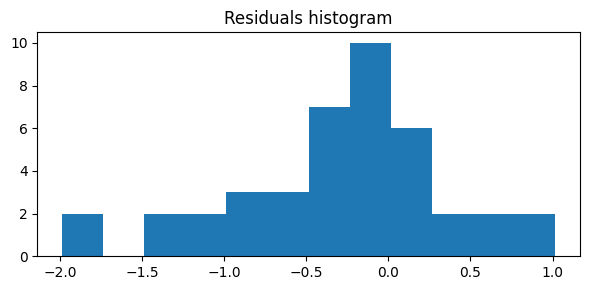

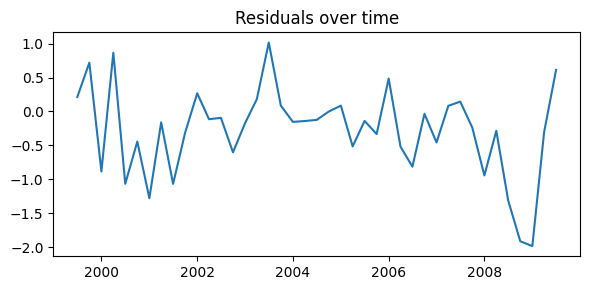

In [ ]:
# 13. Residuals
results['residual'] = results['actual_qoq'] - results['predicted_qoq']

# Histogram of residuals
plt.figure(figsize=(6,3))
plt.hist(results['residual'].dropna(), bins=12)
plt.title("Residuals histogram")
plt.tight_layout()
plt.show()

# Residuals over time
plt.figure(figsize=(6,3))
plt.plot(results.index, results['residual'])
plt.title("Residuals over time")
plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


/tmp/ipython-input-2625231977.py:17: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  future_dates = pd.date_range(


,forecast_qoq
date,
2009-09-30,0.136384
2009-12-31,0.160125
2010-03-31,0.213694
2010-06-30,0.244076
2010-09-30,0.320457
2010-12-31,0.426538
2011-03-31,0.543292
2011-06-30,0.594194


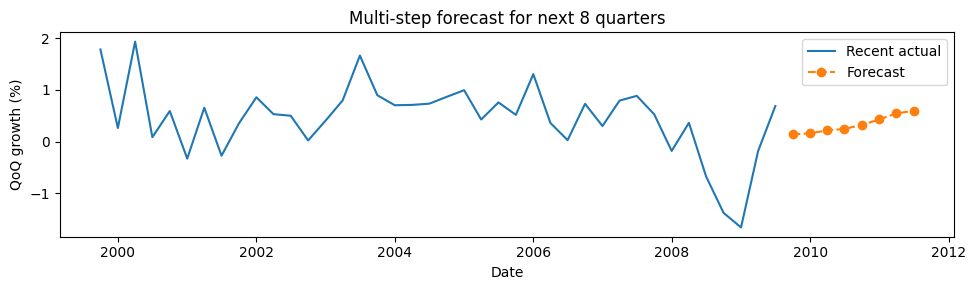

Lab finished. Visuals produced for each stage.


In [ ]:
# 14. Iterative multi-step forecast (8 quarters ahead)
last_seq = np.vstack([train_scaled, test_scaled])[-SEQ_LEN:].flatten()
forecast_steps = 8
forecast_scaled = []
cur = last_seq.copy()

for i in range(forecast_steps):
    inp = cur[-SEQ_LEN:].reshape((1, SEQ_LEN, 1))
    p = model.predict(inp)[0,0]
    forecast_scaled.append(p)
    cur = np.append(cur, p)

# Invert scaling
forecast = scaler.inverse_transform(np.array(forecast_scaled).reshape(-1,1)).flatten()

# Create future date index
future_dates = pd.date_range(
    start=series.index[-1] + pd.offsets.QuarterBegin(),
    periods=forecast_steps,
    freq='Q'
)

forecast_df = pd.DataFrame({'date': future_dates, 'forecast_qoq': forecast}).set_index('date')
display(forecast_df)

# Plot forecast with recent history
plt.figure(figsize=(10,3))
plt.plot(series.index[-40:], series['qoq_growth'].values[-40:], label='Recent actual')
plt.plot(forecast_df.index, forecast_df['forecast_qoq'], linestyle='--', marker='o', label='Forecast')
plt.title("Multi-step forecast for next 8 quarters")
plt.xlabel("Date")
plt.ylabel("QoQ growth (%)")
plt.legend()
plt.tight_layout()
plt.show()

print("Lab finished. Visuals produced for each stage.")